In [5]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/tanjimshaharia/bangla-stylo/final_bangla_stylometry_long_300.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nCondition counts:")
print(df["condition"].value_counts())

print("\nMissing values:")
print(df.isna().sum().sum())

Dataset shape: (300, 4)

Columns:
['topic_id', 'topic', 'condition', 'text']

Condition counts:
condition
human                  100
llm                    100
machine_translation    100
Name: count, dtype: int64

Missing values:
0


In [6]:
import re
import numpy as np
from collections import Counter

def extract_stylometric_features(text):
    text = str(text)

    # Tokenize Bangla, English and numbers
    words = re.findall(
        r'[\u0980-\u09FF]+|[A-Za-z]+(?:[-’\'][A-Za-z]+)?|\d+',
        text
    )

    word_count = len(words)

    # Remove numbers for lexical features
    normalized_words = [
        w.lower()
        for w in words
        if not w.isdigit()
    ]

    unique_words = len(set(normalized_words))

    # Sentence segmentation
    sentences = [
        s.strip()
        for s in re.split(r'[।!?]+', text)
        if s.strip()
    ]

    sentence_count = len(sentences)

    avg_sentence_length = (
        word_count / sentence_count
        if sentence_count > 0
        else 0
    )

    avg_word_length = (
        np.mean([
            len(w)
            for w in words
            if not w.isdigit()
        ])
        if normalized_words
        else 0
    )

    # Lexical diversity
    type_token_ratio = (
        unique_words / len(normalized_words)
        if normalized_words
        else 0
    )

    root_ttr = (
        unique_words / np.sqrt(len(normalized_words))
        if normalized_words
        else 0
    )

    # Character features
    char_count = len(text)

    bangla_chars = len(
        re.findall(r'[\u0980-\u09FF]', text)
    )

    alphabetic_chars = len(
        re.findall(r'[\u0980-\u09FFA-Za-z]', text)
    )

    bangla_char_ratio = (
        bangla_chars / alphabetic_chars
        if alphabetic_chars > 0
        else 0
    )

    # Punctuation
    comma_count = text.count(',')
    fullstop_count = text.count('।')
    question_count = text.count('?')
    exclamation_count = text.count('!')

    punctuation_count = (
        comma_count
        + fullstop_count
        + question_count
        + exclamation_count
    )

    # Numbers
    digit_count = len(
        re.findall(r'\d', text)
    )

    # Repetition
    word_counts = Counter(normalized_words)

    repeated_words = sum(
        count
        for count in word_counts.values()
        if count > 1
    )

    repeated_word_ratio = (
        repeated_words / len(normalized_words)
        if normalized_words
        else 0
    )

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "avg_sentence_length": avg_sentence_length,
        "avg_word_length": avg_word_length,
        "unique_word_count": unique_words,
        "type_token_ratio": type_token_ratio,
        "root_ttr": root_ttr,
        "char_count": char_count,
        "punctuation_count": punctuation_count,
        "comma_count": comma_count,
        "fullstop_count": fullstop_count,
        "question_count": question_count,
        "exclamation_count": exclamation_count,
        "digit_count": digit_count,
        "bangla_char_ratio": bangla_char_ratio,
        "repeated_word_ratio": repeated_word_ratio
    }


# Extract features from all 300 texts
feature_values = df["text"].apply(
    extract_stylometric_features
)

features_df = pd.concat(
    [
        df[
            ["topic_id", "topic", "condition"]
        ].reset_index(drop=True),

        pd.DataFrame(
            feature_values.tolist()
        )
    ],
    axis=1
)

print("Feature dataset shape:", features_df.shape)

print("\nMissing values:")
print(features_df.isna().sum().sum())

print("\nFirst 5 rows:")
display(features_df.head())

Feature dataset shape: (300, 19)

Missing values:
0

First 5 rows:


,topic_id,topic,condition,word_count,sentence_count,avg_sentence_length,avg_word_length,unique_word_count,type_token_ratio,root_ttr,char_count,punctuation_count,comma_count,fullstop_count,question_count,exclamation_count,digit_count,bangla_char_ratio,repeated_word_ratio
0,1,Traffic congestion in Dhaka,human,151,12,12.583333,5.364238,110,0.728477,8.951673,975,15,3,12,0,0,0,1.0,0.490066
1,2,Air pollution in Bangladesh,human,151,13,11.615385,5.597122,91,0.654676,7.718519,993,15,2,13,0,0,35,1.0,0.546763
2,3,Water pollution in Bangladesh,human,151,13,11.615385,5.482517,98,0.685315,8.195172,975,20,7,13,0,0,19,1.0,0.489510
3,4,Plastic waste management,human,150,9,16.666667,5.333333,113,0.753333,9.226411,961,12,3,9,0,0,0,1.0,0.426667
4,5,Flooding in Bangladesh,human,157,9,17.444444,5.393548,99,0.638710,7.951871,1016,20,11,9,0,0,4,1.0,0.541935


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

# Features for ML
ml_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

X = features_df[ml_features]
y = features_df["condition"]
groups = features_df["topic_id"]

# 5-fold stratified + grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("X shape:", X.shape)
print("Number of topics:", groups.nunique())

print("\nClass distribution:")
print(y.value_counts())

print("\nChecking topic leakage:\n")

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    train_topics = set(groups.iloc[train_idx])
    test_topics = set(groups.iloc[test_idx])

    overlap = train_topics.intersection(test_topics)

    print(
        f"Fold {fold}: "
        f"train={len(train_idx)}, "
        f"test={len(test_idx)}, "
        f"topic overlap={len(overlap)}"
    )

X shape: (300, 16)
Number of topics: 100

Class distribution:
condition
human                  100
llm                    100
machine_translation    100
Name: count, dtype: int64

Checking topic leakage:

Fold 1: train=240, test=60, topic overlap=0
Fold 2: train=240, test=60, topic overlap=0
Fold 3: train=240, test=60, topic overlap=0
Fold 4: train=240, test=60, topic overlap=0
Fold 5: train=240, test=60, topic overlap=0


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Logistic Regression pipeline
logreg_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Cross-validated predictions
y_pred = cross_val_predict(
    logreg_model,
    X,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy = accuracy_score(y, y_pred)

macro_f1 = f1_score(
    y,
    y_pred,
    average="macro"
)

print("Logistic Regression Results")
print("=" * 35)

print(f"Accuracy : {accuracy:.4f}")
print(f"Macro F1 : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred
    )
)

Logistic Regression Results
Accuracy : 0.9367
Macro F1 : 0.9368

Classification Report:
                     precision    recall  f1-score   support

              human     0.9216    0.9400    0.9307       100
                llm     0.9065    0.9700    0.9372       100
machine_translation     0.9890    0.9000    0.9424       100

           accuracy                         0.9367       300
          macro avg     0.9390    0.9367    0.9368       300
       weighted avg     0.9390    0.9367    0.9368       300


Confusion Matrix:
[[94  5  1]
 [ 3 97  0]
 [ 5  5 90]]


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Cross-validated predictions
y_pred_rf = cross_val_predict(
    rf_model,
    X,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy_rf = accuracy_score(y, y_pred_rf)

macro_f1_rf = f1_score(
    y,
    y_pred_rf,
    average="macro"
)

print("Random Forest Results")
print("=" * 35)

print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Macro F1 : {macro_f1_rf:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_rf,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_rf
    )
)

Random Forest Results
Accuracy : 0.9433
Macro F1 : 0.9431

Classification Report:
                     precision    recall  f1-score   support

              human     0.9340    0.9900    0.9612       100
                llm     0.9216    0.9400    0.9307       100
machine_translation     0.9783    0.9000    0.9375       100

           accuracy                         0.9433       300
          macro avg     0.9446    0.9433    0.9431       300
       weighted avg     0.9446    0.9433    0.9431       300


Confusion Matrix:
[[99  1  0]
 [ 4 94  2]
 [ 3  7 90]]


In [11]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
])

# Cross-validated predictions
y_pred_svm = cross_val_predict(
    svm_model,
    X,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy_svm = accuracy_score(y, y_pred_svm)

macro_f1_svm = f1_score(
    y,
    y_pred_svm,
    average="macro"
)

print("SVM Results")
print("=" * 35)

print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Macro F1 : {macro_f1_svm:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_svm,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_svm
    )
)

SVM Results
Accuracy : 0.9333
Macro F1 : 0.9331

Classification Report:
                     precision    recall  f1-score   support

              human     0.9223    0.9500    0.9360       100
                llm     0.9151    0.9700    0.9417       100
machine_translation     0.9670    0.8800    0.9215       100

           accuracy                         0.9333       300
          macro avg     0.9348    0.9333    0.9331       300
       weighted avg     0.9348    0.9333    0.9331       300


Confusion Matrix:
[[95  2  3]
 [ 3 97  0]
 [ 5  7 88]]


In [12]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Encode target labels
label_map = {
    "human": 0,
    "llm": 1,
    "machine_translation": 2
}

y_encoded = y.map(label_map)

# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Cross-validated predictions
y_pred_xgb = cross_val_predict(
    xgb_model,
    X,
    y_encoded,
    cv=cv,
    groups=groups
)

# Convert predictions back to original labels
inverse_label_map = {
    0: "human",
    1: "llm",
    2: "machine_translation"
}

y_pred_xgb_labels = pd.Series(y_pred_xgb).map(inverse_label_map)

# Metrics
accuracy_xgb = accuracy_score(y, y_pred_xgb_labels)

macro_f1_xgb = f1_score(
    y,
    y_pred_xgb_labels,
    average="macro"
)

print("XGBoost Results")
print("=" * 35)

print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Macro F1 : {macro_f1_xgb:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_xgb_labels,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_xgb_labels
    )
)

XGBoost Results
Accuracy : 0.9467
Macro F1 : 0.9467

Classification Report:
                     precision    recall  f1-score   support

              human     0.9327    0.9700    0.9510       100
                llm     0.9400    0.9400    0.9400       100
machine_translation     0.9688    0.9300    0.9490       100

           accuracy                         0.9467       300
          macro avg     0.9471    0.9467    0.9467       300
       weighted avg     0.9471    0.9467    0.9467       300


Confusion Matrix:
[[97  2  1]
 [ 4 94  2]
 [ 3  4 93]]


XGBoost Feature Importance


,feature,importance
0,unique_word_count,0.183725
1,word_count,0.170142
2,digit_count,0.153726
3,fullstop_count,0.069743
4,type_token_ratio,0.064783
5,bangla_char_ratio,0.056533
6,root_ttr,0.055587
7,sentence_count,0.054860
8,repeated_word_ratio,0.047726
9,punctuation_count,0.040399


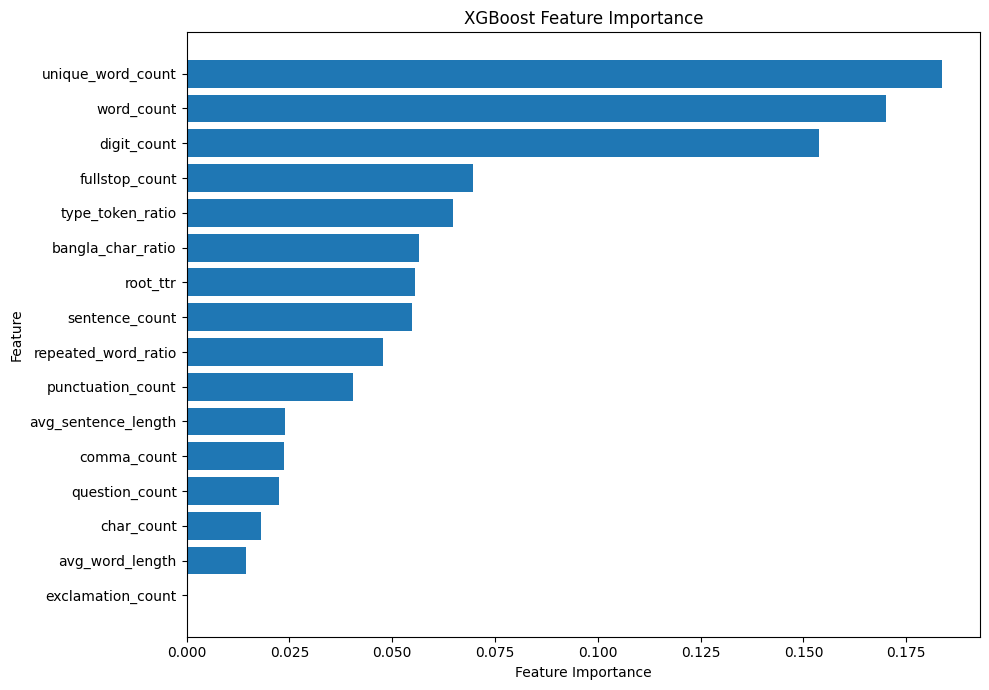

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Fit XGBoost on the full dataset for feature-importance inspection
xgb_importance_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_importance_model.fit(X, y_encoded)

# Extract feature importance
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": xgb_importance_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("XGBoost Feature Importance")
print("=" * 40)
display(importance_df)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

In [14]:
# Features less directly dependent on overall text length
controlled_features = [
    "avg_sentence_length",
    "avg_word_length",
    "type_token_ratio",
    "root_ttr",
    "bangla_char_ratio",
    "repeated_word_ratio",
    "question_count",
    "exclamation_count"
]

X_controlled = features_df[controlled_features]

# XGBoost with length-controlled features
xgb_controlled = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Cross-validated predictions
y_pred_controlled = cross_val_predict(
    xgb_controlled,
    X_controlled,
    y_encoded,
    cv=cv,
    groups=groups
)

# Convert predictions back to labels
y_pred_controlled_labels = pd.Series(
    y_pred_controlled
).map(inverse_label_map)

# Metrics
accuracy_controlled = accuracy_score(
    y,
    y_pred_controlled_labels
)

macro_f1_controlled = f1_score(
    y,
    y_pred_controlled_labels,
    average="macro"
)

print("Length-Controlled XGBoost Results")
print("=" * 40)

print(f"Accuracy : {accuracy_controlled:.4f}")
print(f"Macro F1 : {macro_f1_controlled:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_controlled_labels,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_controlled_labels
    )
)

Length-Controlled XGBoost Results
Accuracy : 0.8367
Macro F1 : 0.8372

Classification Report:
                     precision    recall  f1-score   support

              human     0.7980    0.7900    0.7940       100
                llm     0.8019    0.8500    0.8252       100
machine_translation     0.9158    0.8700    0.8923       100

           accuracy                         0.8367       300
          macro avg     0.8386    0.8367    0.8372       300
       weighted avg     0.8386    0.8367    0.8372       300


Confusion Matrix:
[[79 16  5]
 [12 85  3]
 [ 8  5 87]]


In [15]:
# Logistic Regression with reduced feature set

logreg_controlled = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Cross-validated predictions
y_pred_lr_controlled = cross_val_predict(
    logreg_controlled,
    X_controlled,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy_lr_controlled = accuracy_score(
    y,
    y_pred_lr_controlled
)

macro_f1_lr_controlled = f1_score(
    y,
    y_pred_lr_controlled,
    average="macro"
)

print("Length-Controlled Logistic Regression Results")
print("=" * 50)

print(f"Accuracy : {accuracy_lr_controlled:.4f}")
print(f"Macro F1 : {macro_f1_lr_controlled:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_lr_controlled,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_lr_controlled
    )
)

Length-Controlled Logistic Regression Results
Accuracy : 0.8633
Macro F1 : 0.8637

Classification Report:
                     precision    recall  f1-score   support

              human     0.8365    0.8700    0.8529       100
                llm     0.8431    0.8600    0.8515       100
machine_translation     0.9149    0.8600    0.8866       100

           accuracy                         0.8633       300
          macro avg     0.8649    0.8633    0.8637       300
       weighted avg     0.8649    0.8633    0.8637       300


Confusion Matrix:
[[87  9  4]
 [10 86  4]
 [ 7  7 86]]


In [16]:
# Random Forest with reduced feature set

rf_controlled = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Cross-validated predictions
y_pred_rf_controlled = cross_val_predict(
    rf_controlled,
    X_controlled,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy_rf_controlled = accuracy_score(
    y,
    y_pred_rf_controlled
)

macro_f1_rf_controlled = f1_score(
    y,
    y_pred_rf_controlled,
    average="macro"
)

print("Length-Controlled Random Forest Results")
print("=" * 50)

print(f"Accuracy : {accuracy_rf_controlled:.4f}")
print(f"Macro F1 : {macro_f1_rf_controlled:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_rf_controlled,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_rf_controlled
    )
)

Length-Controlled Random Forest Results
Accuracy : 0.8433
Macro F1 : 0.8431

Classification Report:
                     precision    recall  f1-score   support

              human     0.8144    0.7900    0.8020       100
                llm     0.8257    0.9000    0.8612       100
machine_translation     0.8936    0.8400    0.8660       100

           accuracy                         0.8433       300
          macro avg     0.8446    0.8433    0.8431       300
       weighted avg     0.8446    0.8433    0.8431       300


Confusion Matrix:
[[79 13  8]
 [ 8 90  2]
 [10  6 84]]


In [17]:
# SVM with reduced feature set

svm_controlled = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
])

# Cross-validated predictions
y_pred_svm_controlled = cross_val_predict(
    svm_controlled,
    X_controlled,
    y,
    cv=cv,
    groups=groups
)

# Metrics
accuracy_svm_controlled = accuracy_score(
    y,
    y_pred_svm_controlled
)

macro_f1_svm_controlled = f1_score(
    y,
    y_pred_svm_controlled,
    average="macro"
)

print("Length-Controlled SVM Results")
print("=" * 40)

print(f"Accuracy : {accuracy_svm_controlled:.4f}")
print(f"Macro F1 : {macro_f1_svm_controlled:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred_svm_controlled,
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y,
        y_pred_svm_controlled
    )
)


Length-Controlled SVM Results
Accuracy : 0.8633
Macro F1 : 0.8634

Classification Report:
                     precision    recall  f1-score   support

              human     0.8333    0.8500    0.8416       100
                llm     0.8364    0.9200    0.8762       100
machine_translation     0.9318    0.8200    0.8723       100

           accuracy                         0.8633       300
          macro avg     0.8672    0.8633    0.8634       300
       weighted avg     0.8672    0.8633    0.8634       300


Confusion Matrix:
[[85 11  4]
 [ 6 92  2]
 [11  7 82]]


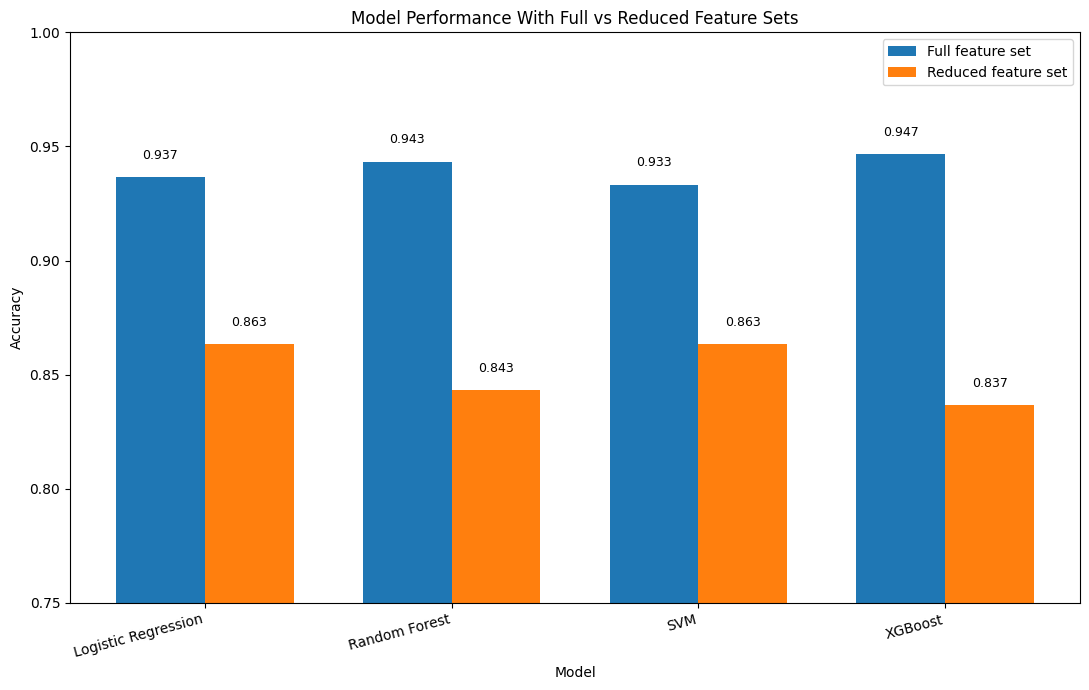

Saved:
/kaggle/working/ml_figures/model_performance_full_vs_reduced.png


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Model performance data
models = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "XGBoost"
]

full_accuracy = [
    0.9367,
    0.9433,
    0.9333,
    0.9467
]

controlled_accuracy = [
    0.8633,
    0.8433,
    0.8633,
    0.8367
]

x = np.arange(len(models))
width = 0.36

plt.figure(figsize=(11, 7))

plt.bar(
    x - width/2,
    full_accuracy,
    width,
    label="Full feature set"
)

plt.bar(
    x + width/2,
    controlled_accuracy,
    width,
    label="Reduced feature set"
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Performance With Full vs Reduced Feature Sets")

plt.xticks(
    x,
    models,
    rotation=15,
    ha="right"
)

plt.ylim(0.75, 1.0)

plt.legend()

# Add value labels
for i, value in enumerate(full_accuracy):
    plt.text(
        i - width/2,
        value + 0.008,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

for i, value in enumerate(controlled_accuracy):
    plt.text(
        i + width/2,
        value + 0.008,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

# Save
output_dir = "/kaggle/working/ml_figures"
os.makedirs(output_dir, exist_ok=True)

plt.savefig(
    f"{output_dir}/model_performance_full_vs_reduced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(f"{output_dir}/model_performance_full_vs_reduced.png")

Reduced-Feature XGBoost Importance


,feature,importance
3,root_ttr,0.221705
6,question_count,0.165600
2,type_token_ratio,0.148360
4,bangla_char_ratio,0.132627
0,avg_sentence_length,0.131078
5,repeated_word_ratio,0.129838
1,avg_word_length,0.070792
7,exclamation_count,0.000000


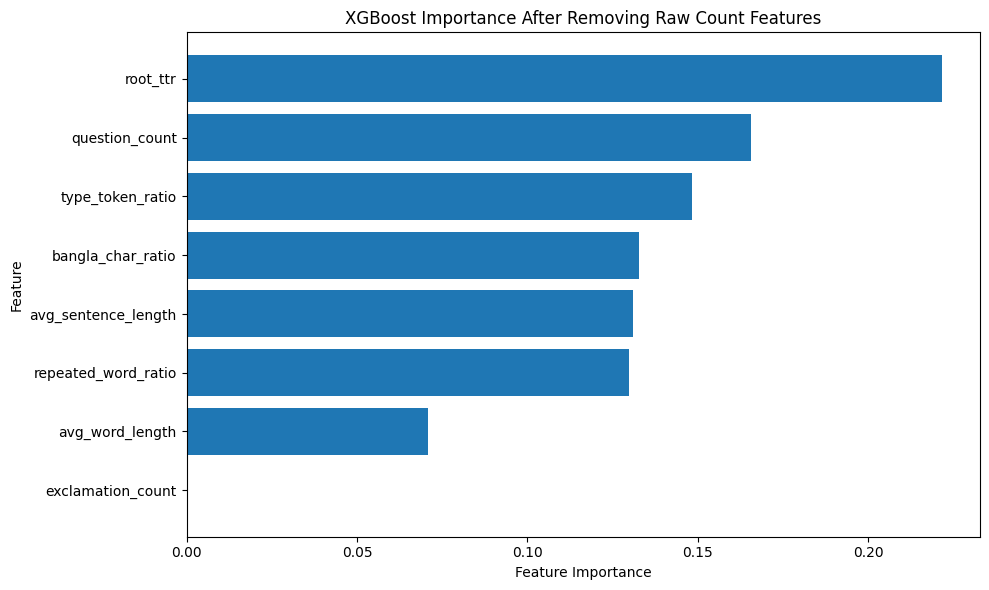


Saved:
/kaggle/working/ml_figures/xgboost_reduced_feature_importance.png


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Fit reduced-feature XGBoost on the full dataset
xgb_controlled_importance = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_controlled_importance.fit(
    X_controlled,
    y_encoded
)

# Feature importance
controlled_importance_df = pd.DataFrame({
    "feature": X_controlled.columns,
    "importance": xgb_controlled_importance.feature_importances_
})

controlled_importance_df = controlled_importance_df.sort_values(
    "importance",
    ascending=True
)

print("Reduced-Feature XGBoost Importance")
print("=" * 45)
display(
    controlled_importance_df.sort_values(
        "importance",
        ascending=False
    )
)

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    controlled_importance_df["feature"],
    controlled_importance_df["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Importance After Removing Raw Count Features")

plt.tight_layout()

output_dir = "/kaggle/working/ml_figures"
os.makedirs(output_dir, exist_ok=True)

plt.savefig(
    f"{output_dir}/xgboost_reduced_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(f"{output_dir}/xgboost_reduced_feature_importance.png")

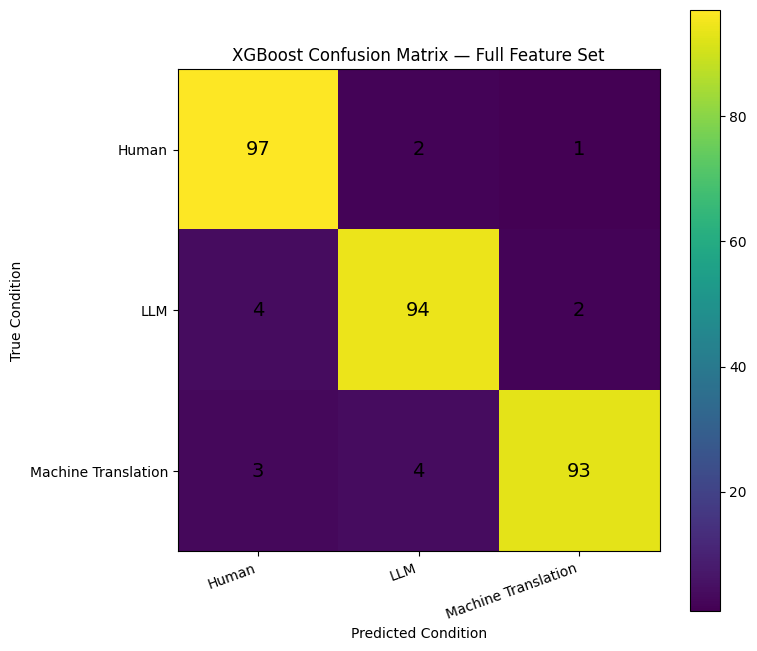

Confusion matrix:
[[97  2  1]
 [ 4 94  2]
 [ 3  4 93]]

Saved:
/kaggle/working/ml_figures/xgboost_confusion_matrix.png


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Final full-feature XGBoost confusion matrix
cm = np.array([
    [97, 2, 1],
    [4, 94, 2],
    [3, 4, 93]
])

labels = [
    "Human",
    "LLM",
    "Machine Translation"
]

plt.figure(figsize=(8, 7))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(3),
    labels,
    rotation=20,
    ha="right"
)

plt.yticks(
    range(3),
    labels
)

plt.xlabel("Predicted Condition")
plt.ylabel("True Condition")
plt.title("XGBoost Confusion Matrix — Full Feature Set")

# Add values
for i in range(3):
    for j in range(3):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

output_dir = "/kaggle/working/ml_figures"
os.makedirs(output_dir, exist_ok=True)

plt.savefig(
    f"{output_dir}/xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)

print("\nSaved:")
print(f"{output_dir}/xgboost_confusion_matrix.png")